# Dense vs Convolutional Neural Networks


In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torchvision
from torch import nn, optim
from torchvision import transforms

torch.random.manual_seed(0)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)


cpu


Link to the data:
https://drive.google.com/drive/folders/1VjQNIKuGGU7G-CZMsmFIn__M_v7nywEZ?usp=sharing

_(this is a subset of "skin-cancer-mnist-ham10000")_


Read the CSV file and display the first few rows of the data.

In [2]:
df = pd.read_csv("../data/HAM2000/HAM2000.csv")
full_name = {
    "bcc": "Basal cell carcinoma",
    "bkl": "Benign keratosis-like lesions",
    "mel": "Melanoma",
    "nv": "Melanocytic nevi",
}
df["dx_full"] = df["dx"].map(full_name.get)
df.head()


,lesion_id,image_id,dx,dx_type,age,sex,localization,dx_full
0,HAM_0006518,ISIC_0027618,nv,follow_up,35.0,male,back,Melanocytic nevi
1,HAM_0004666,ISIC_0029165,nv,follow_up,55.0,male,upper extremity,Melanocytic nevi
2,HAM_0006455,ISIC_0029690,nv,follow_up,50.0,male,lower extremity,Melanocytic nevi
3,HAM_0003653,ISIC_0030139,nv,histo,45.0,male,back,Melanocytic nevi
4,HAM_0001330,ISIC_0026818,nv,histo,20.0,female,abdomen,Melanocytic nevi


Create a dataset with a transformation to resize the images to 64x64 pixels.

Add data augmentation (random horizontal/vertical flip) to the dataset.

In [3]:
transfo = transforms.Compose(
    [
        transforms.Resize((64, 64)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.ToTensor(),
    ]
)
dataset = torchvision.datasets.ImageFolder(root="../data/HAM2000/", transform=transfo)
class_names = [full_name[name] for name in dataset.find_classes("../data/HAM2000/")[0]]


Split the dataset into training and test sets.

Create dataloaders for the training and test sets.

In [4]:
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [train_size, test_size]
)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64)


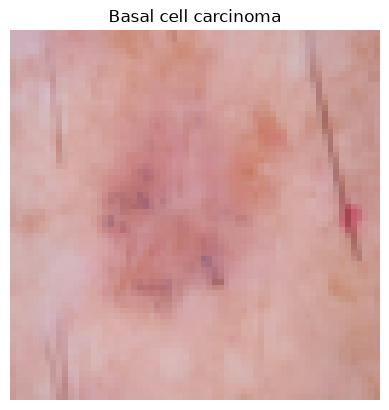

In [5]:
image, label = dataset[0]
plt.imshow(image.permute(1, 2, 0))
plt.title(class_names[label])
plt.axis("off")
plt.show()


### Linear Model

Create a linear model with two hidden layer, with batch normalization.

In [6]:
class SkinLinearNet(nn.Module):
    def __init__(self, hidden_size1=512, hidden_size2=32):
        super().__init__()
        self.fc0 = nn.Linear(3*64*64, hidden_size1)
        self.fc1 = nn.Linear(hidden_size1, hidden_size2)
        self.fc2 = nn.Linear(hidden_size2, 4)
        self.bn0 = nn.BatchNorm1d(hidden_size1)
        self.bn1 = nn.BatchNorm1d(hidden_size2)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)
        
    def forward(self, x):
        x = x.view(-1, 3*64*64)
        x = self.relu(self.bn0(self.fc0(x)))
        x = self.relu(self.bn1(self.fc1(x)))
        x = self.softmax(self.fc2(x))
        return x

Create a loss function and an optimizer.

In [7]:
model = SkinLinearNet()
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss()

num_epochs = 10
losses = []
accuracies = [0.25]

Write the training loop.

In [8]:
model.train()  # batch norm uses the batch statistics (and updates its running averages)
for epoch in range(1, num_epochs + 1):
    running_loss = 0.0
    correct_count = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        hot_outputs = model(images)
        outputs = hot_outputs.argmax(axis=1)
        correct_count += (outputs == labels).sum().item()
        loss = criterion(hot_outputs, labels)
        loss.backward()
        losses.append(loss.item())
        running_loss += loss.item()
        optimizer.step()
        optimizer.zero_grad()
    accuracy = correct_count/train_size
    accuracies.append(accuracy)
    print(f"Epoch [{epoch}/{num_epochs}] Loss: {running_loss:.6f} Accuracy: {accuracy*100:.2f}%")


Epoch [1/10] Loss: 31.563081 Accuracy: 52.88%


Epoch [2/10] Loss: 30.456091 Accuracy: 57.88%


Epoch [3/10] Loss: 30.001996 Accuracy: 61.62%


Epoch [4/10] Loss: 29.789211 Accuracy: 62.25%


Epoch [5/10] Loss: 29.445734 Accuracy: 63.81%


Epoch [6/10] Loss: 29.170115 Accuracy: 65.69%


Epoch [7/10] Loss: 29.092159 Accuracy: 65.69%


Epoch [8/10] Loss: 28.975351 Accuracy: 66.38%


Epoch [9/10] Loss: 28.636769 Accuracy: 66.81%


Epoch [10/10] Loss: 28.550479 Accuracy: 66.94%


Plot the loss and accuracy through epochs.

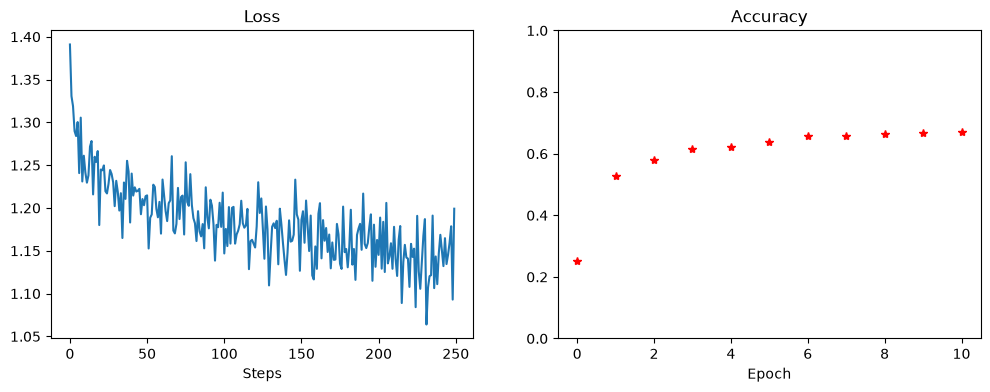

In [9]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(losses)
plt.title("Loss")
plt.xlabel("Steps")
plt.subplot(1,2,2)
plt.plot(accuracies, '*r')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylim(0, 1)
plt.show()


Test the model on a few images of the test set.

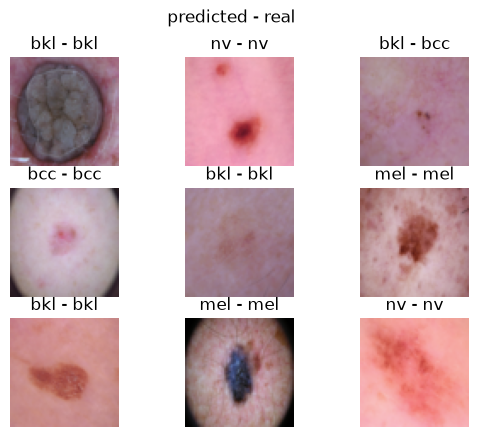

In [10]:
small_class_names = dataset.find_classes("../data/HAM2000/")[0]
model.eval()  # batch norm uses its running averages
for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    predictions = model(images)
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(images[i].cpu().numpy().swapaxes(0, 2).swapaxes(0, 1))
        pred_class = small_class_names[torch.argmax(predictions[i])]
        real_class = small_class_names[labels[i]]
        ax.set_title(f"{pred_class} - {real_class}")
        plt.axis("off")
    plt.suptitle("predicted - real")
    plt.show()
    break


Compute the accuracy of the model on the test set.

In [11]:
model.eval()  # batch norm uses its running averages
correct = 0
total = 0
for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    predictions = model(images)
    total += labels.size(0)
    correct += (torch.argmax(predictions, dim=1) == labels).sum().item()

print(f"Accuracy: {100*correct/total:.2f} %")


Accuracy: 58.25 %


### Conv Model

Create a convolutional model with a few convolutional layers and two linear layers (for the classification), with batch normalization.

In [12]:
class SkinConvNet(nn.Module):
    def __init__(self, hidden_size=64):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 5, stride=2)
        self.conv2 = nn.Conv2d(8, 16, 5, stride=1)
        self.conv3 = nn.Conv2d(16, 32, 5, stride=1)
        self.conv4 = nn.Conv2d(32, 32, 5, stride=1)
        self.conv5 = nn.Conv2d(32, 32, 5, stride=1)
        self.bn1 = nn.BatchNorm2d(8)
        self.bn2 = nn.BatchNorm2d(16)
        self.bn3 = nn.BatchNorm2d(32)
        self.bn4 = nn.BatchNorm2d(32)
        self.bn5 = nn.BatchNorm2d(32)
        self.fc1 = nn.Linear(14 * 14 * 32, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 4)
        self.bn_fc1 = nn.BatchNorm1d(hidden_size)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        x = self.relu(self.bn5(self.conv5(x)))
        # print(x.shape)
        x = x.view(-1, 14 * 14 * 32)
        x = self.relu(self.bn_fc1(self.fc1(x)))
        x = self.softmax(self.fc2(x))
        return x


Create a loss function and an optimizer.

In [13]:
model = SkinConvNet()
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss()

num_epochs = 10
losses = []
accuracies = [0.25]

Write the training loop.

In [14]:
model.train()  # batch norm uses the batch statistics (and updates its running averages)
for epoch in range(1, num_epochs + 1):
    running_loss = 0.0
    correct_count = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)
        hot_outputs = model(images)
        outputs = hot_outputs.argmax(axis=1)
        correct_count += (outputs == labels).sum().item()
        loss = criterion(hot_outputs, labels)
        loss.backward()
        losses.append(loss.item())
        running_loss += loss.item()
        optimizer.step()
        optimizer.zero_grad()
    accuracy = correct_count/train_size
    accuracies.append(accuracy)
    print(f"Epoch [{epoch}/{num_epochs}] Loss: {running_loss:.6f} Accuracy: {accuracy*100:.2f}%")


Epoch [1/10] Loss: 31.772410 Accuracy: 48.50%


Epoch [2/10] Loss: 29.665712 Accuracy: 58.69%


Epoch [3/10] Loss: 28.974819 Accuracy: 61.81%


Epoch [4/10] Loss: 28.511586 Accuracy: 62.44%


Epoch [5/10] Loss: 28.354946 Accuracy: 64.06%


Epoch [6/10] Loss: 27.919415 Accuracy: 65.81%


Epoch [7/10] Loss: 27.563518 Accuracy: 67.50%


Epoch [8/10] Loss: 27.265860 Accuracy: 69.94%


Epoch [9/10] Loss: 27.102729 Accuracy: 69.81%


Epoch [10/10] Loss: 26.667256 Accuracy: 72.06%


Plot the loss and accuracy through epochs.

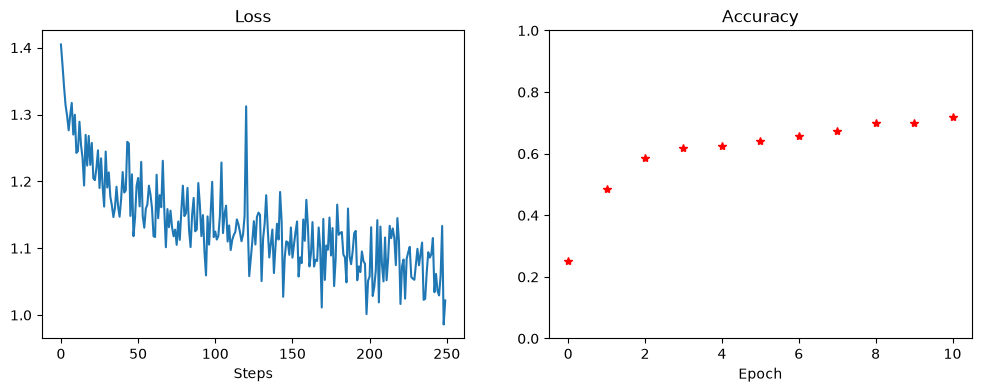

In [15]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(losses)
plt.title("Loss")
plt.xlabel("Steps")
plt.subplot(1,2,2)
plt.plot(accuracies, '*r')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylim(0, 1)
plt.show()


Test the model on a few images of the test set.

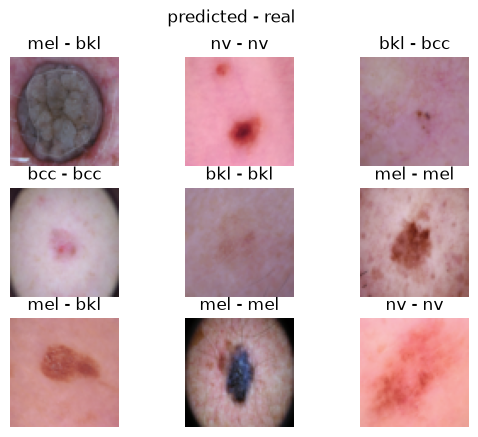

In [16]:
small_class_names = dataset.find_classes("../data/HAM2000/")[0]
model.eval()  # batch norm uses its running averages
for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    predictions = model(images)
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(images[i].cpu().numpy().swapaxes(0, 2).swapaxes(0, 1))
        pred_class = small_class_names[torch.argmax(predictions[i])]
        real_class = small_class_names[labels[i]]
        ax.set_title(f"{pred_class} - {real_class}")
        plt.axis("off")
    plt.suptitle("predicted - real")
    plt.show()
    break


Compute the accuracy of the model on the test set.

In [17]:
model.eval()  # batch norm uses its running averages
correct = 0
total = 0
for images, labels in test_loader:
    images = images.to(device)
    labels = labels.to(device)
    predictions = model(images)
    total += labels.size(0)
    correct += (torch.argmax(predictions, dim=1) == labels).sum().item()

print(f"Accuracy: {100*correct/total:.2f} %")


Accuracy: 60.25 %


Compare the training time and accuracy of the two models.

In [18]:
for model_class in [SkinLinearNet, SkinConvNet]:
    n_params = sum(p.numel() for p in model_class().parameters())
    print(f"{model_class.__name__}: {n_params:,} parameters")

SkinLinearNet: 6,309,604 parameters
SkinConvNet: 470,020 parameters


- **Parameters**: the linear model has ~6.3M parameters (almost all in the first layer, $3 \times 64 \times 64 \times 512$), the convolutional one only ~0.47M (mostly in `fc1`); the batch norms add almost nothing (2 parameters per channel/neuron: ~1k for the linear model, ~400 for the conv one): the convolutions share their weights over the whole image.
- **Training time**: despite having ~13x fewer parameters, the convolutional model is *slower* to train: each image requires ~23M multiply-adds (the same small kernels are applied at every position) vs ~6.3M for the linear model.
- **Accuracy**: with batch normalization, both models train much faster than without it (~50% training accuracy after the first epoch instead of ~27%). After 10 epochs, the convolutional model reaches ~72% on the training set and ~60% on the test set, vs ~67% / ~58% for the linear model (25% for chance on 4 balanced classes). The gap between training and test accuracy shows that both models start to overfit; training longer and/or with bigger images should favor the convolutional model, which overfits less thanks to its smaller number of parameters.

-----

BONUS: Create a custom dataset and return the image, the class, and some tabular data from the CSV file.

You may use the 'bis' version of the dataset for this task:
https://drive.google.com/drive/folders/1VjQNIKuGGU7G-CZMsmFIn__M_v7nywEZ?usp=sharing

2000 images, 19 tabular features: ['age', 'sex_female', 'sex_male', 'sex_unknown', 'localization_abdomen', 'localization_acral', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_foot', 'localization_genital', 'localization_hand', 'localization_lower extremity', 'localization_neck', 'localization_scalp', 'localization_trunk', 'localization_unknown', 'localization_upper extremity']


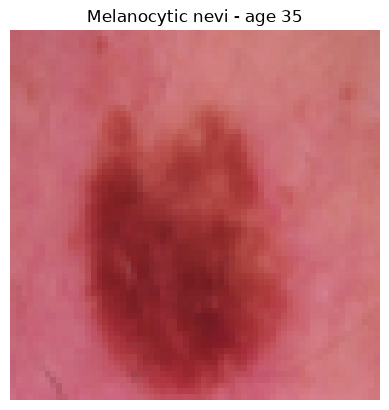

In [19]:
from PIL import Image


class SkinDataset(torch.utils.data.Dataset):
    def __init__(self, root, transform=None):
        self.transform = transform
        df = pd.read_csv(os.path.join(root, "metadata.csv"))
        # find the image of each row, whatever the folder structure
        paths = {}
        for dirpath, _, filenames in os.walk(root):
            for filename in filenames:
                name, ext = os.path.splitext(filename)
                if ext.lower() in (".jpg", ".jpeg", ".png"):
                    paths[name] = os.path.join(dirpath, filename)
        df = df[df["image_id"].isin(paths)].reset_index(drop=True)
        self.paths = [paths[image_id] for image_id in df["image_id"]]
        self.classes = sorted(df["dx"].unique())
        self.labels = torch.tensor(df["dx"].map(self.classes.index).values)
        # tabular data: age (normalized) + one-hot encoded sex & localization
        # (we do NOT use dx_type: it is how the diagnosis was made, so it leaks the label)
        age = df["age"].fillna(df["age"].mean()) / 100
        one_hot = pd.get_dummies(df[["sex", "localization"]], dtype=float)
        self.tabular_names = ["age"] + list(one_hot.columns)
        self.tabular = torch.tensor(
            pd.concat([age, one_hot], axis=1).values, dtype=torch.float32
        )

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        image = Image.open(self.paths[idx]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.tabular[idx], self.labels[idx]


tab_dataset = SkinDataset("../data/HAM/", transform=transfo)
n_tabular = tab_dataset.tabular.shape[1]
print(len(tab_dataset), "images,", n_tabular, "tabular features:", tab_dataset.tabular_names)

tab_train_size = int(0.8 * len(tab_dataset))
tab_test_size = len(tab_dataset) - tab_train_size
tab_train_dataset, tab_test_dataset = torch.utils.data.random_split(
    tab_dataset, [tab_train_size, tab_test_size]
)
tab_train_loader = torch.utils.data.DataLoader(tab_train_dataset, batch_size=64, shuffle=True)
tab_test_loader = torch.utils.data.DataLoader(tab_test_dataset, batch_size=64)

image, tabular, label = tab_dataset[0]
plt.imshow(image.permute(1, 2, 0))
plt.title(f"{full_name[tab_dataset.classes[label]]} - age {100*tabular[0]:.0f}")
plt.axis("off")
plt.show()

Create a model that uses the tabular data and the image to predict the class.

In [20]:
class SkinMixedNet(nn.Module):
    def __init__(self, n_tabular, hidden_size=64, tabular_hidden_size=16):
        super().__init__()
        # image branch (same as SkinConvNet)
        self.conv1 = nn.Conv2d(3, 8, 5, stride=2)
        self.conv2 = nn.Conv2d(8, 16, 5, stride=1)
        self.conv3 = nn.Conv2d(16, 32, 5, stride=1)
        self.conv4 = nn.Conv2d(32, 32, 5, stride=1)
        self.conv5 = nn.Conv2d(32, 32, 5, stride=1)
        self.bn1 = nn.BatchNorm2d(8)
        self.bn2 = nn.BatchNorm2d(16)
        self.bn3 = nn.BatchNorm2d(32)
        self.bn4 = nn.BatchNorm2d(32)
        self.bn5 = nn.BatchNorm2d(32)
        # tabular branch
        self.fc_tab = nn.Linear(n_tabular, tabular_hidden_size)
        self.bn_tab = nn.BatchNorm1d(tabular_hidden_size)
        # classification head, on the concatenation of both branches
        self.fc1 = nn.Linear(14 * 14 * 32 + tabular_hidden_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, 4)
        self.bn_fc1 = nn.BatchNorm1d(hidden_size)
        self.relu = nn.ReLU()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x, tab):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.relu(self.bn3(self.conv3(x)))
        x = self.relu(self.bn4(self.conv4(x)))
        x = self.relu(self.bn5(self.conv5(x)))
        x = x.view(-1, 14 * 14 * 32)
        tab = self.relu(self.bn_tab(self.fc_tab(tab)))
        x = torch.cat([x, tab], dim=1)
        x = self.relu(self.bn_fc1(self.fc1(x)))
        x = self.softmax(self.fc2(x))
        return x

Create a loss function and an optimizer.

In [21]:
model = SkinMixedNet(n_tabular)
model.to(device)

optimizer = optim.Adam(model.parameters(), lr=0.0001)
criterion = nn.CrossEntropyLoss()

num_epochs = 10
losses = []
accuracies = [0.25]

Write the training loop.

In [22]:
model.train()  # batch norm uses the batch statistics (and updates its running averages)
for epoch in range(1, num_epochs + 1):
    running_loss = 0.0
    correct_count = 0
    for images, tabular, labels in tab_train_loader:
        images = images.to(device)
        tabular = tabular.to(device)
        labels = labels.to(device)
        hot_outputs = model(images, tabular)
        outputs = hot_outputs.argmax(axis=1)
        correct_count += (outputs == labels).sum().item()
        loss = criterion(hot_outputs, labels)
        loss.backward()
        losses.append(loss.item())
        running_loss += loss.item()
        optimizer.step()
        optimizer.zero_grad()
    accuracy = correct_count/tab_train_size
    accuracies.append(accuracy)
    print(f"Epoch [{epoch}/{num_epochs}] Loss: {running_loss:.6f} Accuracy: {accuracy*100:.2f}%")

Epoch [1/10] Loss: 31.981394 Accuracy: 48.94%


Epoch [2/10] Loss: 29.913244 Accuracy: 57.38%


Epoch [3/10] Loss: 29.056323 Accuracy: 60.88%


Epoch [4/10] Loss: 28.459246 Accuracy: 64.06%


Epoch [5/10] Loss: 28.009986 Accuracy: 66.69%


Epoch [6/10] Loss: 27.865406 Accuracy: 66.50%


Epoch [7/10] Loss: 27.662891 Accuracy: 67.88%


Epoch [8/10] Loss: 27.191136 Accuracy: 70.19%


Epoch [9/10] Loss: 26.859362 Accuracy: 71.44%


Epoch [10/10] Loss: 26.711447 Accuracy: 71.94%


Plot the loss and accuracy through epochs.

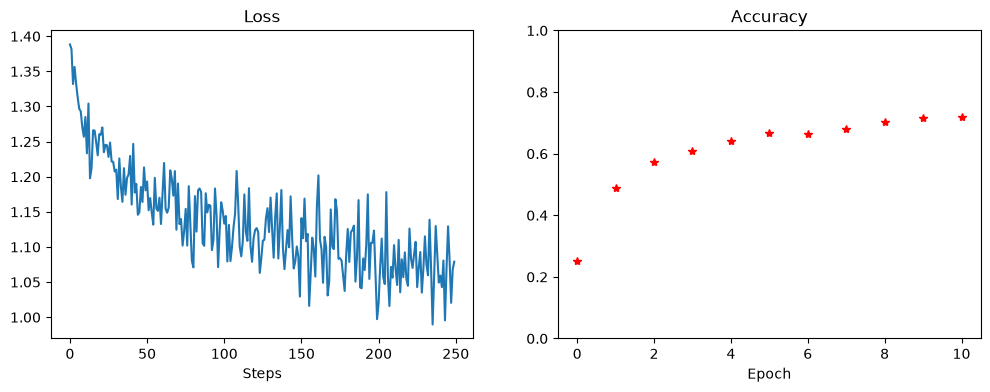

In [23]:
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
plt.plot(losses)
plt.title("Loss")
plt.xlabel("Steps")
plt.subplot(1,2,2)
plt.plot(accuracies, '*r')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylim(0, 1)
plt.show()

Test the model on a few images of the test set.

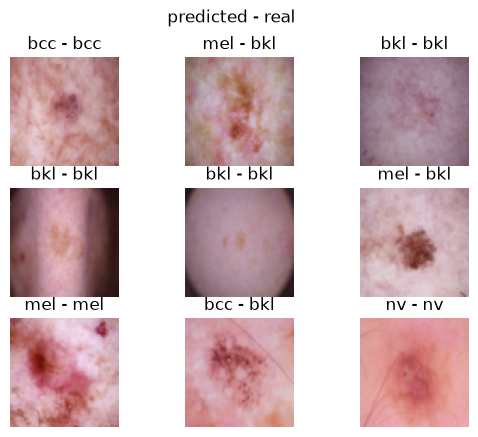

In [24]:
small_class_names = tab_dataset.classes
model.eval()  # batch norm uses its running averages
for images, tabular, labels in tab_test_loader:
    images = images.to(device)
    tabular = tabular.to(device)
    labels = labels.to(device)
    predictions = model(images, tabular)
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(images[i].cpu().numpy().swapaxes(0, 2).swapaxes(0, 1))
        pred_class = small_class_names[torch.argmax(predictions[i])]
        real_class = small_class_names[labels[i]]
        ax.set_title(f"{pred_class} - {real_class}")
        plt.axis("off")
    plt.suptitle("predicted - real")
    plt.show()
    break

Compute the accuracy of the model on the test set.

In [25]:
model.eval()  # batch norm uses its running averages
correct = 0
total = 0
for images, tabular, labels in tab_test_loader:
    images = images.to(device)
    tabular = tabular.to(device)
    labels = labels.to(device)
    predictions = model(images, tabular)
    total += labels.size(0)
    correct += (torch.argmax(predictions, dim=1) == labels).sum().item()

print(f"Accuracy: {100*correct/total:.2f} %")

Accuracy: 67.00 %
